In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.tree import plot_tree
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.feature_selection import RFECV
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.utils import resample
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [103]:
df = pd.read_csv("dati/train.csv")
df.head()

,id,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,...,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii
0,00008ff9,Fall,5,0,Winter,51.0,Fall,16.877316,46.0,50.8,...,4.0,2.0,4.0,55.0,NaN,NaN,NaN,Fall,3.0,2.0
1,000fd460,Summer,9,0,NaN,NaN,Fall,14.035590,48.0,46.0,...,0.0,0.0,0.0,0.0,Fall,46.0,64.0,Summer,0.0,0.0
2,00105258,Summer,10,1,Fall,71.0,Fall,16.648696,56.5,75.6,...,2.0,1.0,1.0,28.0,Fall,38.0,54.0,Summer,2.0,0.0
3,00115b9f,Winter,9,0,Fall,71.0,Summer,18.292347,56.0,81.6,...,3.0,4.0,1.0,44.0,Summer,31.0,45.0,Winter,0.0,1.0
4,0016bb22,Spring,18,1,Summer,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [104]:
print("Valori da predire:", df['sii'].unique())
print("Valori nulli nella colonna target:", df['sii'].isna().sum())
print("Tipo della classe target:", df['sii'].dtype)

# Eliminiamuo le righe con valori NaN nella colonna 'sii'
df = df.dropna(subset=['sii'])
print("Valori nulli nella colonna target dopo il drop:", df['sii'].isna().sum())

# droppiamo le colonne che non ci servono
PCIAT_cols = [col for col in df.columns if 'PCIAT' in col]
df = df.drop(PCIAT_cols, axis=1)
df = df.drop(columns=['id'])

Valori da predire: [ 2.  0.  1. nan  3.]
Valori nulli nella colonna target: 1224
Tipo della classe target: float64
Valori nulli nella colonna target dopo il drop: 0


In [105]:
#                     #
# Feature Engineering #
#                     #

df = df[df['Physical-Weight'] != 0]

# Prendiamo la media tra i valori di BMI
df['Physical-BMI'] = df[['Physical-BMI', 'BIA-BIA_BMI']].mean(axis=1)
df = df.drop(columns=['BIA-BIA_BMI'], axis=1)

# Codifichiamo le varibili stagionali (10 features -> one-hot aggiungerebbe troppe colonne)
season_cols = [col for col in df.columns if 'Season' in col]
df = pd.get_dummies(df, columns=season_cols, drop_first=False)
# season_mapping = {
#     "Summer": 0,
#     "Fall": 1,
#     "Winter": 2,
#     "Spring": 3,
# }

# for col in season_cols:
#     df[col] = df[col].map(season_mapping)

In [106]:
# Elimino le colonne che hanno più del 50% di valori mancanti e che non sono molto correlate con la variabile target
missing_percentage = df.isnull().mean()
columns_to_drop = missing_percentage[missing_percentage > 0.5].index
print(f"Colonne con 50%+ valori mancanti: {list(columns_to_drop)}")

correlation_with_target = df[columns_to_drop].corrwith(df['sii']).abs().sort_values(ascending=False)
print("Correlazione con la variabile target:")
print(correlation_with_target)

high_corr_features = correlation_with_target[correlation_with_target > 0.10].index  
columns_to_really_drop = set(columns_to_drop) - set(high_corr_features)

print(f"Colonne salvate: {list(high_corr_features)}")
df = df.drop(columns=columns_to_really_drop)

Colonne con 50%+ valori mancanti: ['Physical-Waist_Circumference', 'Fitness_Endurance-Max_Stage', 'Fitness_Endurance-Time_Mins', 'Fitness_Endurance-Time_Sec', 'FGC-FGC_GSND', 'FGC-FGC_GSND_Zone', 'FGC-FGC_GSD', 'FGC-FGC_GSD_Zone', 'PAQ_A-PAQ_A_Total']
Correlazione con la variabile target:
Physical-Waist_Circumference    0.272885
FGC-FGC_GSD                     0.163448
FGC-FGC_GSND                    0.149495
Fitness_Endurance-Max_Stage     0.070589
Fitness_Endurance-Time_Mins     0.060628
PAQ_A-PAQ_A_Total               0.045968
FGC-FGC_GSD_Zone                0.023696
Fitness_Endurance-Time_Sec      0.008701
FGC-FGC_GSND_Zone               0.001667
dtype: float64
Colonne salvate: ['Physical-Waist_Circumference', 'FGC-FGC_GSD', 'FGC-FGC_GSND']


In [107]:
df_with_na = df.copy()
for col in df.columns:
   df[col].fillna(round(df[col].mean()), inplace=True)

df = df.astype(float)
df = df.round(2)

/var/folders/zq/gk5f556s7zq33crv9lknkrhm0000gn/T/ipykernel_15174/1670664959.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(round(df[col].mean()), inplace=True)


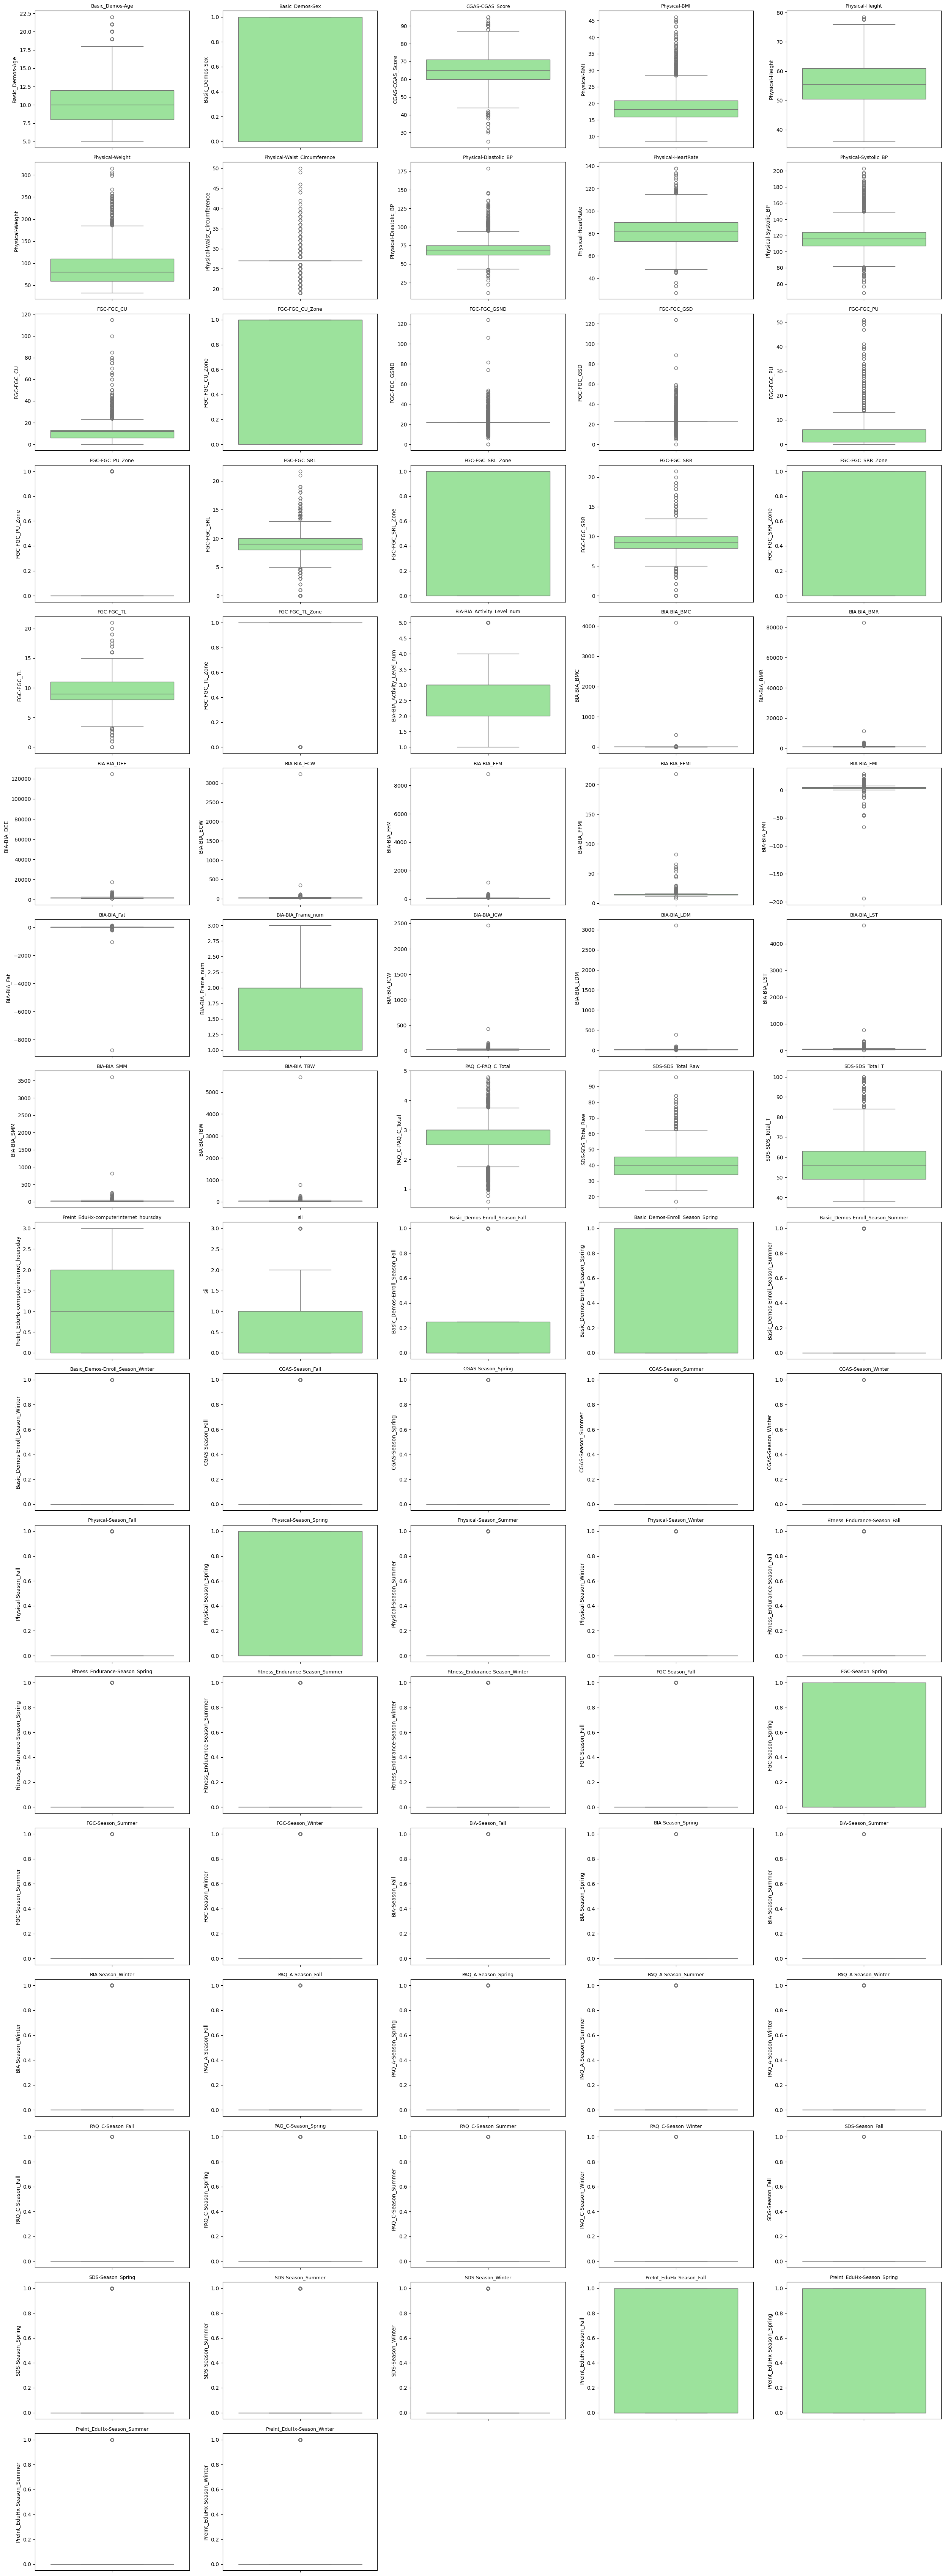

In [108]:
n_cols = len(df.columns)

cols_per_row = 5
n_rows = math.ceil(n_cols / cols_per_row)
plt.figure(figsize=(5 * cols_per_row, 4 * n_rows))

for i, col in enumerate(df.columns, 1):
    plt.subplot(n_rows, cols_per_row, i)
    sns.boxplot(y=df[col], color="lightgreen")
    plt.title(col, fontsize=9)
    plt.tight_layout()

plt.show()


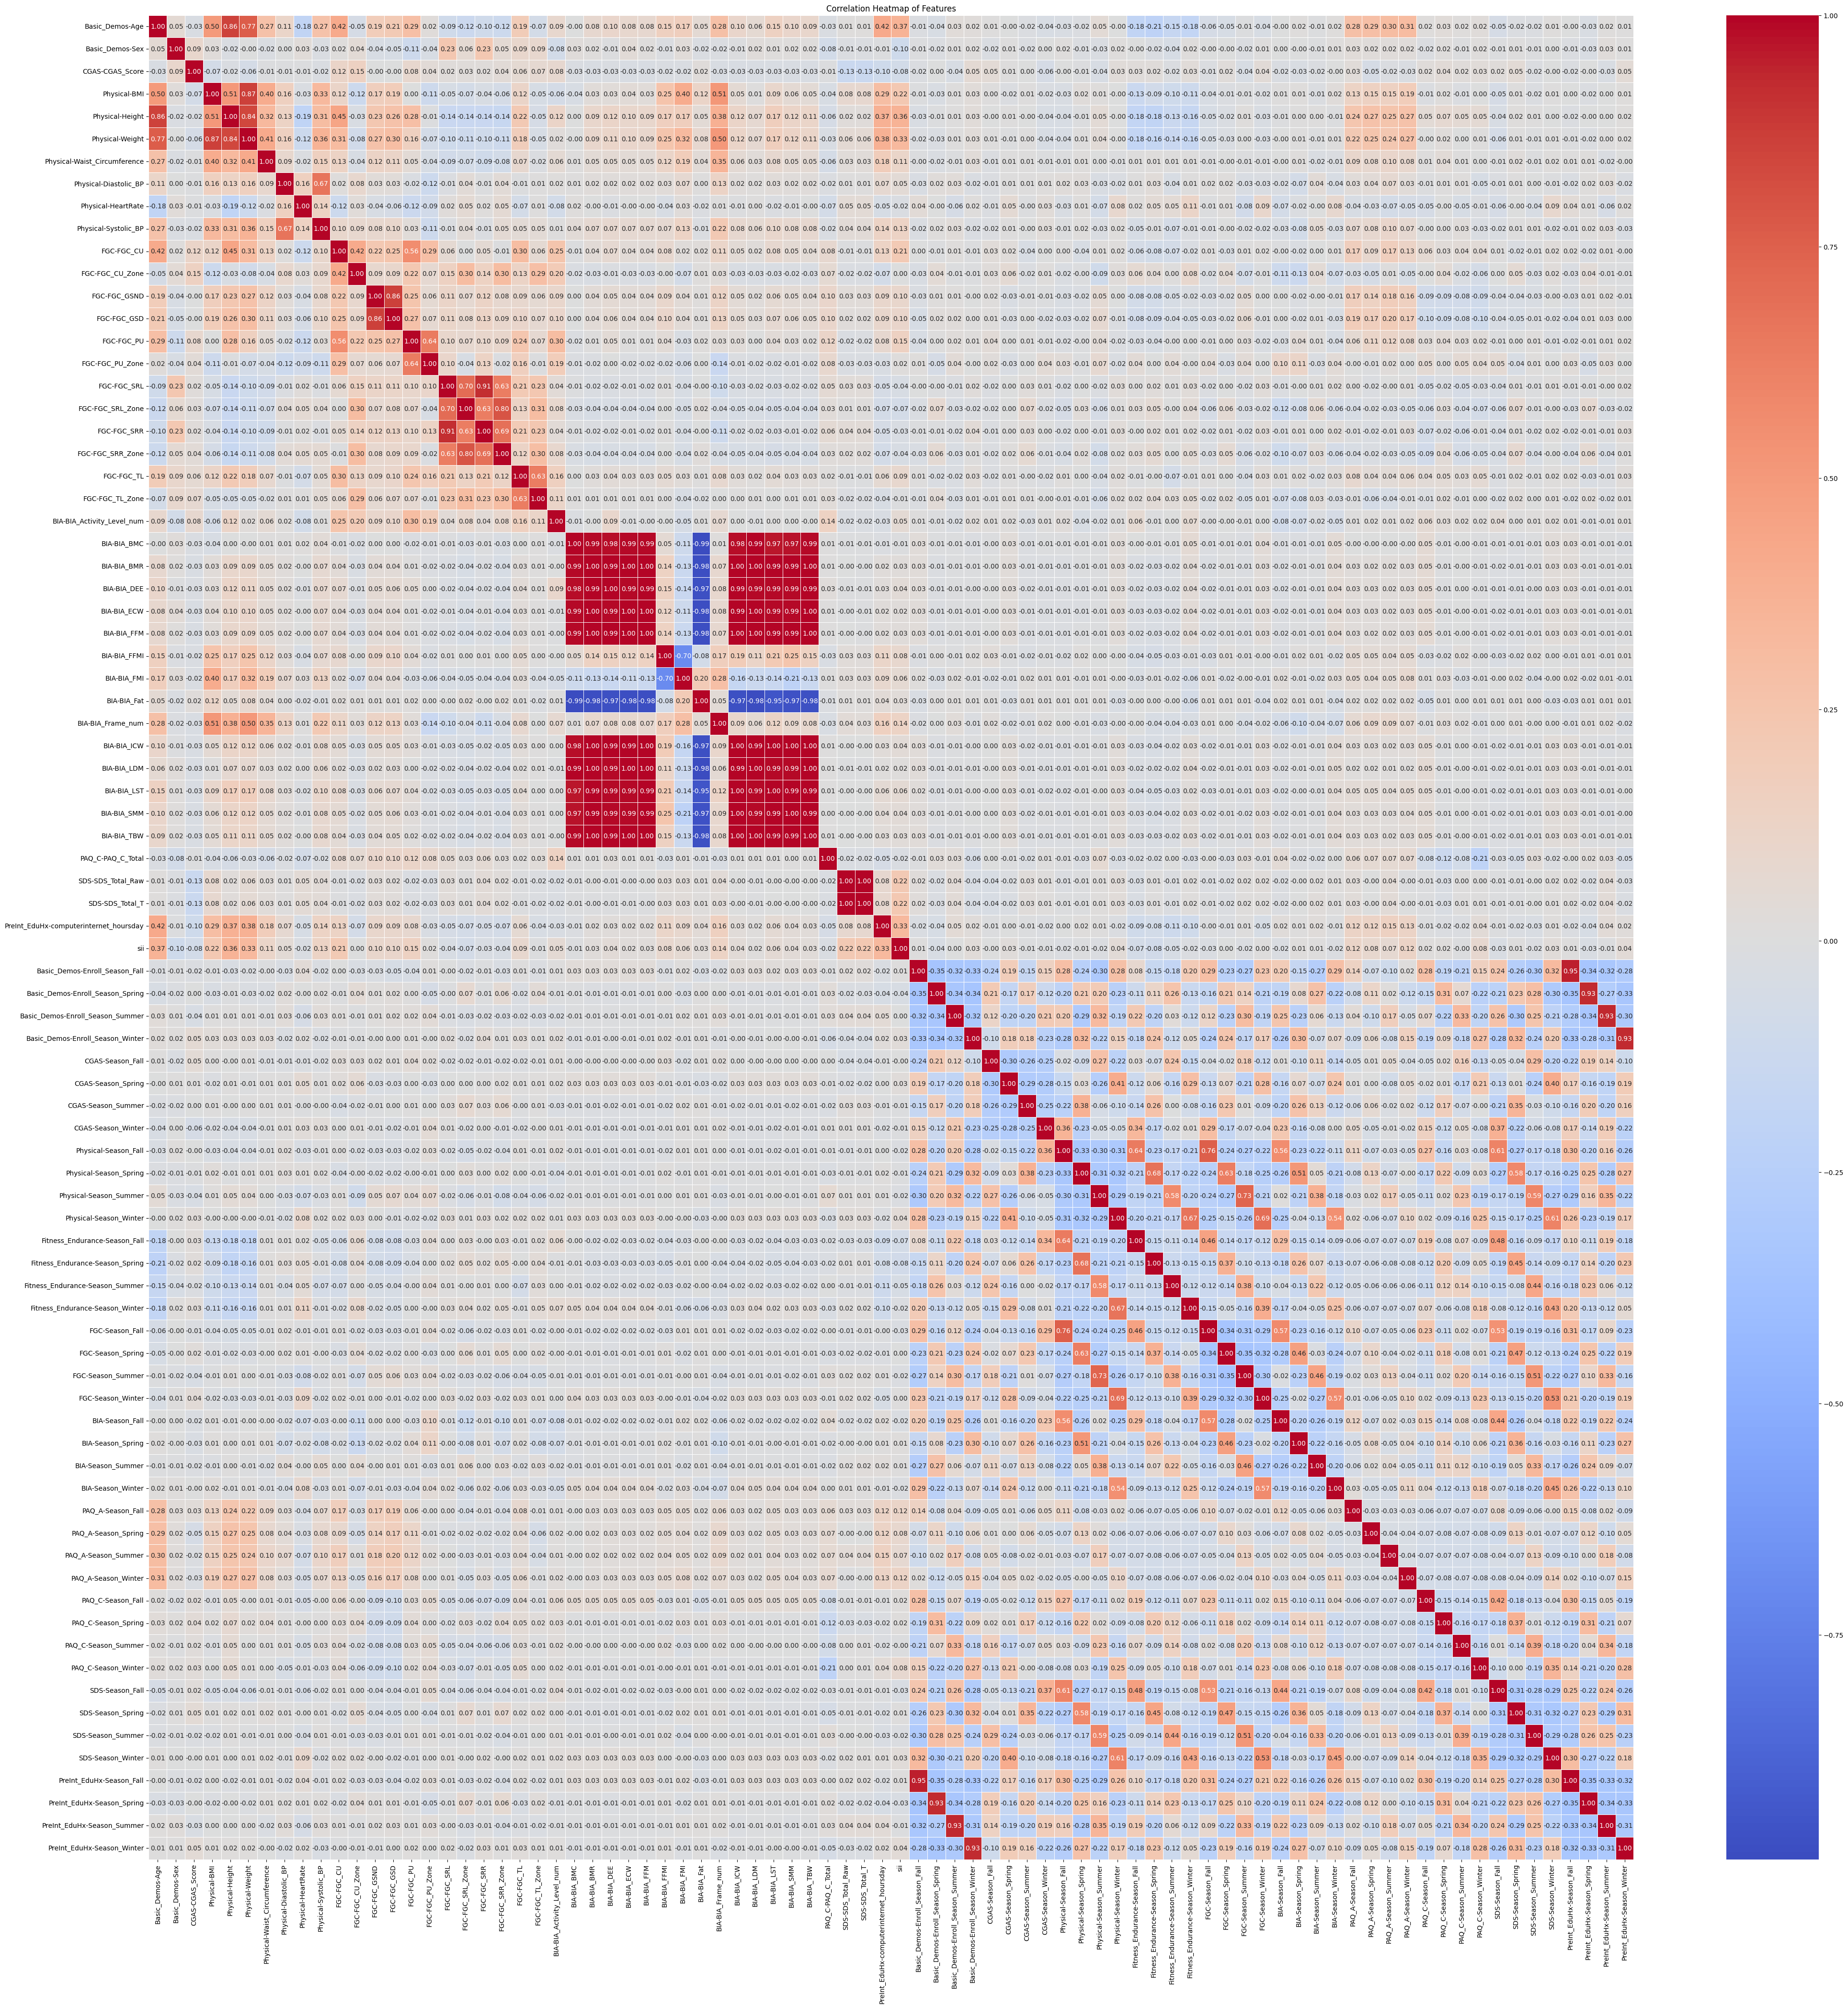

In [109]:
corr_matrix = df.corr()

plt.figure(figsize=(50, 50))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Features")
plt.show()

In [110]:
X = df.drop(columns=['sii'])
y = df['sii']

max_values = df.max()
min_values = df.min()

# Crea un nuovo DataFrame con i valori massimi e minimi
df_min_max = pd.DataFrame({
    'Colonna': df.columns,
    'Valore Minimo': min_values,
    'Valore Massimo': max_values
})

df_min_max

,Colonna,Valore Minimo,Valore Massimo
Basic_Demos-Age,Basic_Demos-Age,5.00,22.00
Basic_Demos-Sex,Basic_Demos-Sex,0.00,1.00
CGAS-CGAS_Score,CGAS-CGAS_Score,25.00,95.00
Physical-BMI,Physical-BMI,8.51,46.11
Physical-Height,Physical-Height,36.00,78.50
...,...,...,...
SDS-Season_Winter,SDS-Season_Winter,0.00,1.00
PreInt_EduHx-Season_Fall,PreInt_EduHx-Season_Fall,0.00,1.00
PreInt_EduHx-Season_Spring,PreInt_EduHx-Season_Spring,0.00,1.00
PreInt_EduHx-Season_Summer,PreInt_EduHx-Season_Summer,0.00,1.00


Feature 'Physical-Height' è fortemente correlata con: ['Basic_Demos-Age'], eliminata.
Feature 'Physical-Weight' è fortemente correlata con: ['Basic_Demos-Age', 'Physical-BMI'], eliminata.
Feature 'FGC-FGC_GSD' è fortemente correlata con: ['FGC-FGC_GSND'], eliminata.
Feature 'FGC-FGC_SRR' è fortemente correlata con: ['FGC-FGC_SRL'], eliminata.
Feature 'FGC-FGC_SRR_Zone' è fortemente correlata con: ['FGC-FGC_SRL_Zone'], eliminata.
Feature 'BIA-BIA_BMR' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_DEE' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_ECW' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_FFM' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_Fat' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_ICW' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_LDM' è fortemente correlata con: ['BIA-BIA_BMC'], eliminata.
Feature 'BIA-BIA_LST'

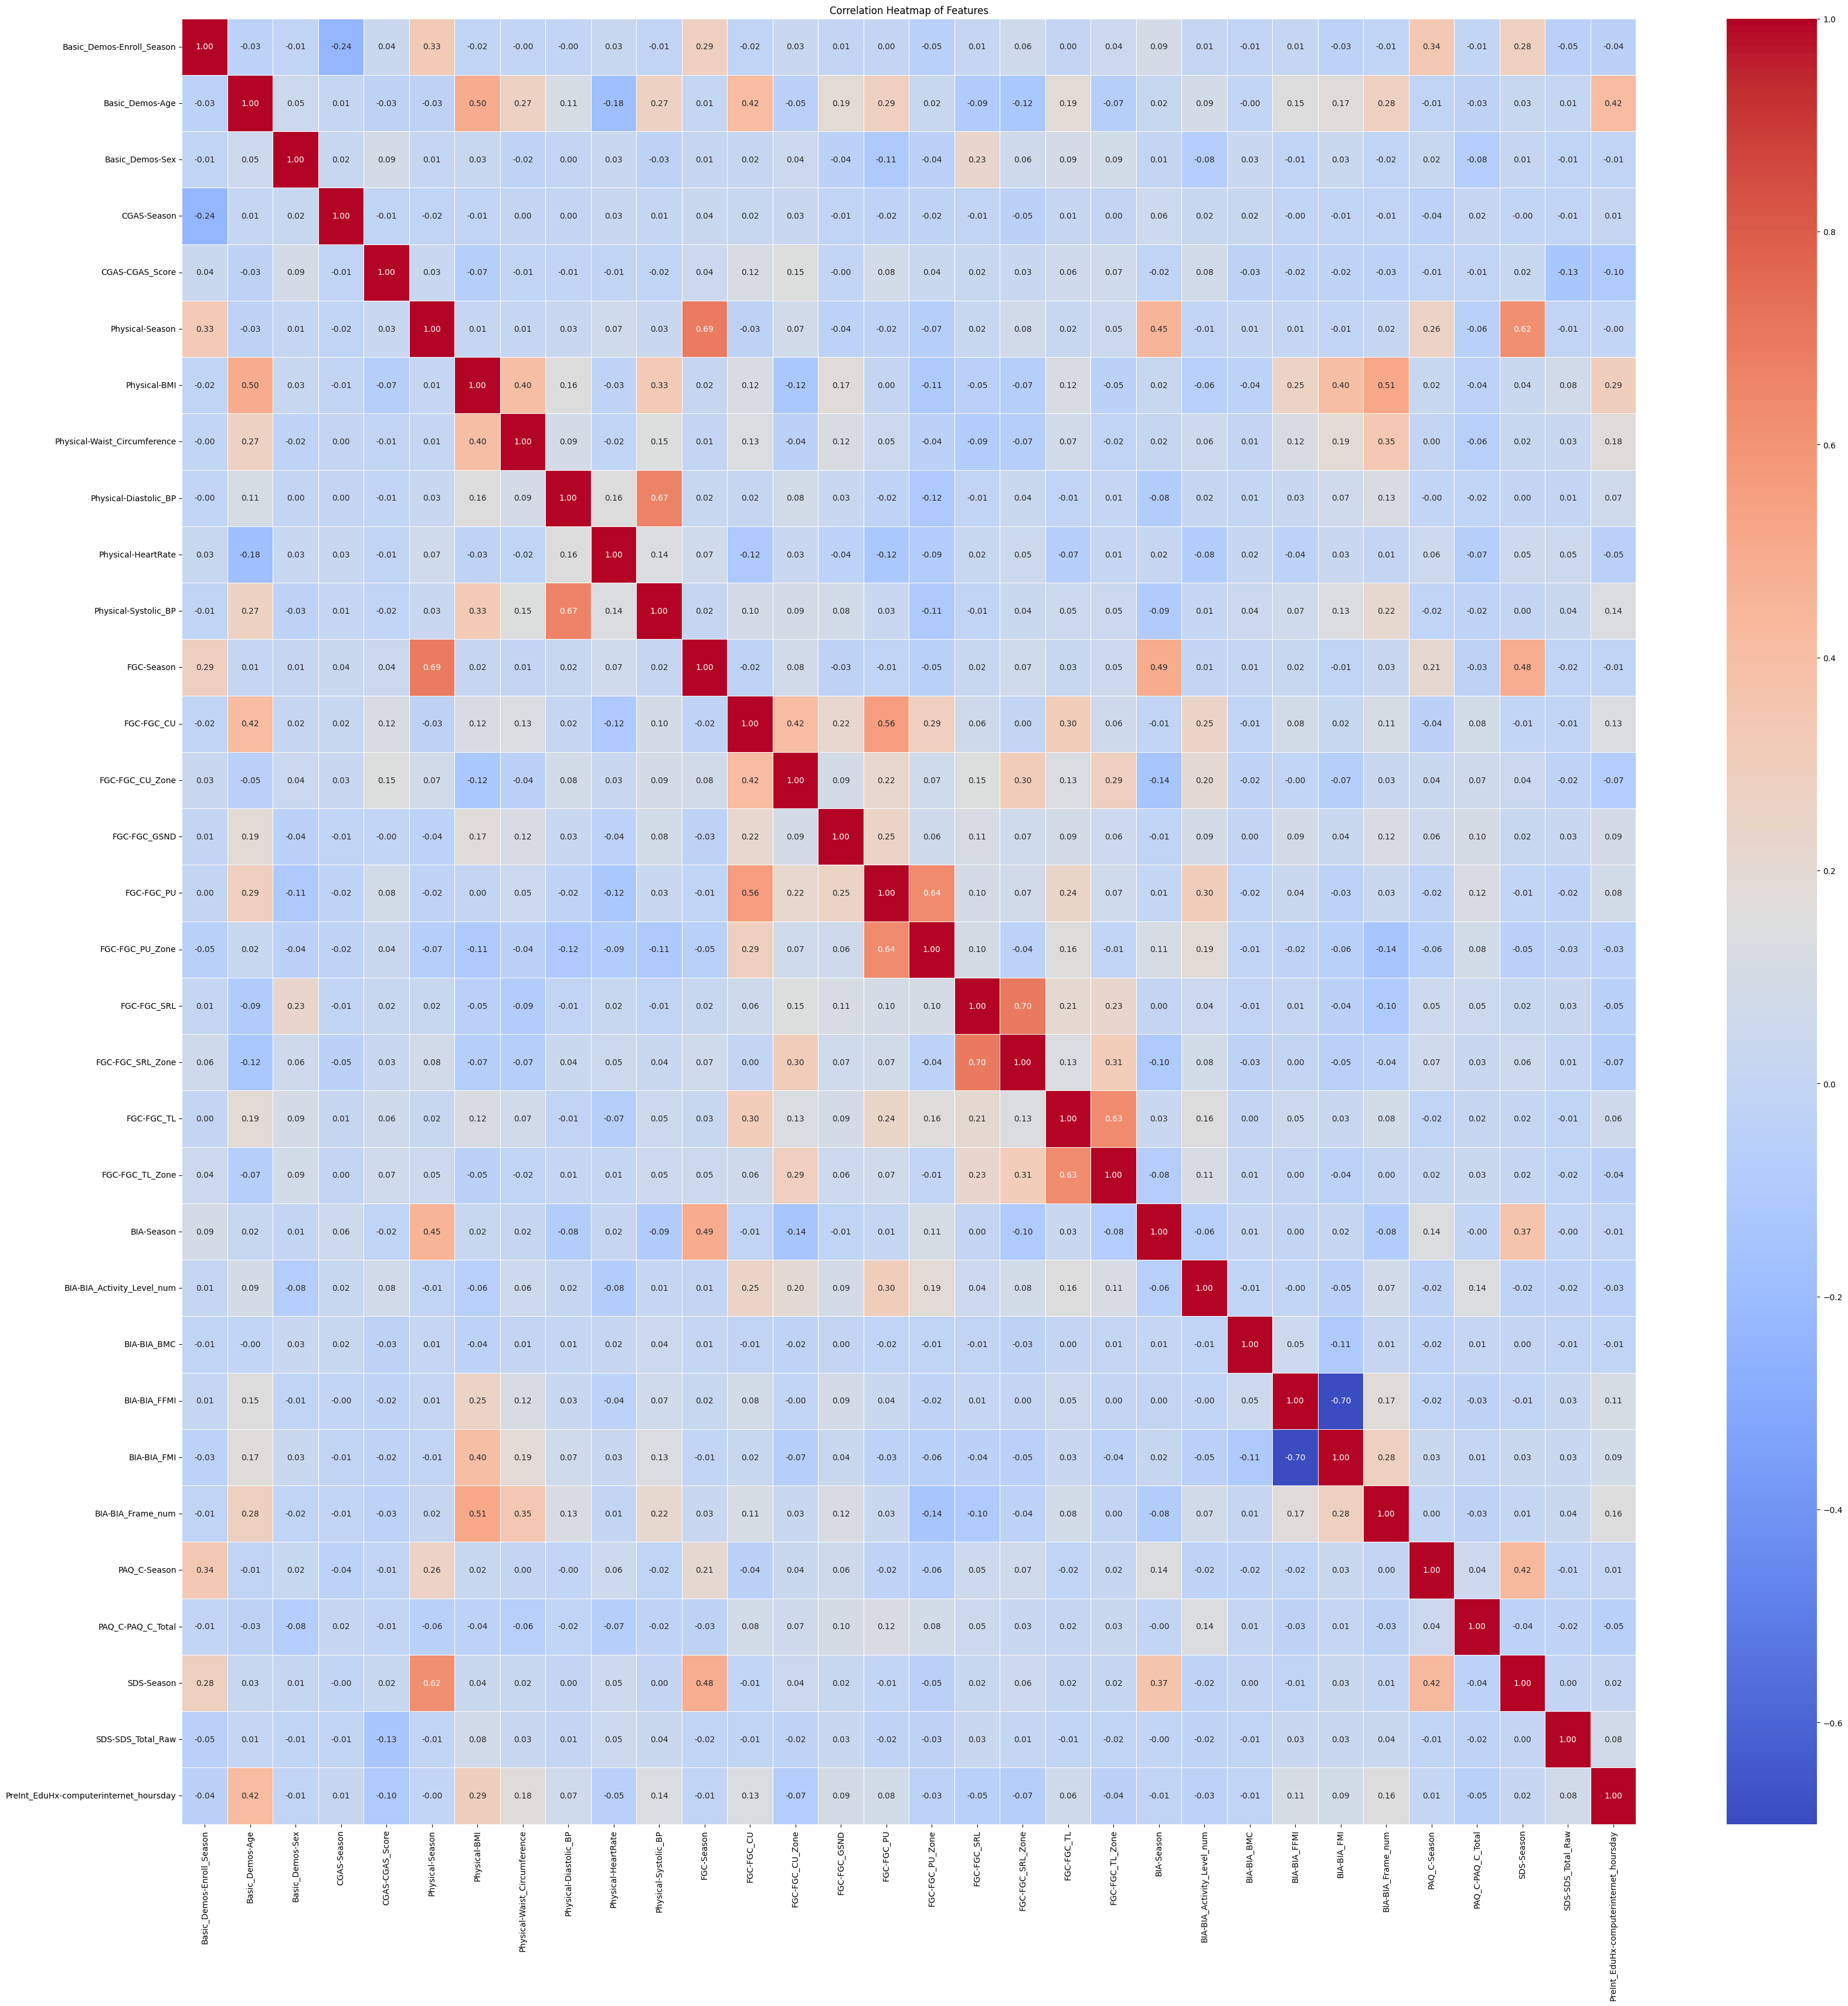

In [ ]:
# Droppiamo le feature con una correlazione > di 0.7 o < di -0.7 -> Troppo correlate tra loro
threshold = 0.7

while True:
    corr_matrix = X.corr()  # Ricalcola la matrice di correlazione
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

    to_drop = None
    for column in upper.columns:
        if any(abs(upper[column]) >= threshold):
            to_drop = column
            break  # Esci dal ciclo appena trovi una feature da eliminare

    if to_drop is None:
        break  # Se non ci sono più feature da eliminare, esci dal ciclo

    correlated_features = upper.index[abs(upper[to_drop]) >= threshold].tolist()
    print(f"Feature '{to_drop}' è fortemente correlata con: {correlated_features}, eliminata.")

    X = X.drop(columns=to_drop)

print(f"Dropped features: {to_drop}")
X.shape

corr_matrix = X.corr()

plt.figure(figsize=(40, 40))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Features")
plt.show()

In [111]:
print("X shape", X.shape)
print("y shape", y.shape)

# Contiamo quanti valori ci sono per ogni classe
# in questo modo capiamo qual è la soglia minima
# predicendo sempre la classe più frequente
print(y.value_counts(normalize=True))

X_train80, X_test20, y_train80, y_test20 = train_test_split(X, y, test_size=0.20, random_state=42)


X shape (2684, 81)
y shape (2684,)
sii
0.0    0.581222
1.0    0.267511
2.0    0.138599
3.0    0.012668
Name: proportion, dtype: float64


In [112]:
# Proviamo con un albero di decisione con tutti i parametri di default
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train80,y_train80)

print("Train acc:", accuracy_score(y_true = y_train80, y_pred = dt.predict(X_train80)))
print("Test acc:", accuracy_score(y_true = y_test20,  y_pred = dt.predict(X_test20)))

scores = cross_val_score(dt, X_train80, y_train80, cv=20)
print("Accuracy media con cv=20:", scores.mean())

Train acc: 1.0
Test acc: 0.5046554934823091
Accuracy media con cv=20: 0.4862712011076497


In [113]:
param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'min_samples_leaf': [10, 25, 50, 100, 150],
    'max_depth': [3, 5, 7, 10],
}

dt = DecisionTreeClassifier(random_state=42)
grid_search_dt = GridSearchCV(estimator=dt, param_grid=param_grid_dt, cv=20, scoring="accuracy", n_jobs=-1)
grid_search_dt.fit(X_train80, y_train80)
print("Best parameters:", grid_search_dt.best_params_)

print(grid_search_dt.best_estimator_)
tuned_dt = grid_search_dt.best_estimator_
tuned_dt.fit(X_train80, y_train80)

train_acc = accuracy_score(y_true=y_train80, y_pred=tuned_dt.predict(X_train80))
test_acc = accuracy_score(y_true=y_test20, y_pred=tuned_dt.predict(X_test20))
print(f"Train Accuracy: {train_acc:.3f}")
print(f"Test Accuracy: {test_acc:.3f}")

scores = cross_val_score(tuned_dt, X_train80, y_train80, cv=20, scoring='accuracy')
print(f"Cross-Validation Accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

feature_importances = tuned_dt.feature_importances_
importance_df = pd.Series(feature_importances, index=X_train80.columns).sort_values(ascending=False)

print(importance_df.head(10))

Best parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 100}
DecisionTreeClassifier(criterion='entropy', max_depth=5, min_samples_leaf=100,
                       random_state=42)
Train Accuracy: 0.619
Test Accuracy: 0.598
Cross-Validation Accuracy: 0.6148 ± 0.0319
Basic_Demos-Age                           0.463488
PreInt_EduHx-computerinternet_hoursday    0.232559
SDS-SDS_Total_T                           0.077417
SDS-SDS_Total_Raw                         0.039871
FGC-FGC_GSND                              0.038362
FGC-FGC_PU                                0.032889
Physical-Weight                           0.028111
Physical-Height                           0.023170
BIA-BIA_SMM                               0.022364
FGC-FGC_CU                                0.017837
dtype: float64


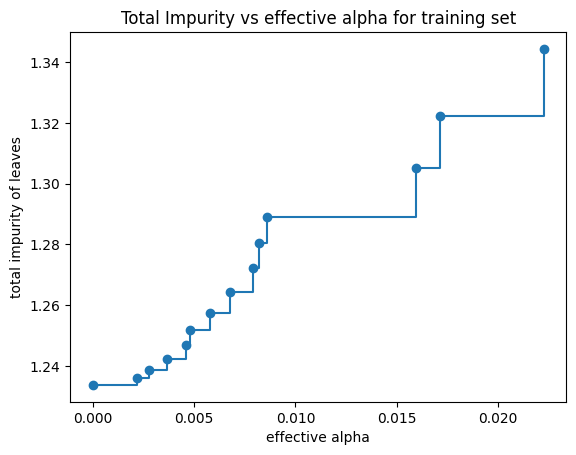

In [114]:
#
# Facciamo pruning
#

path = tuned_dt.cost_complexity_pruning_path(X_train80, y_train80)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

fig, ax = plt.subplots()
ax.plot(ccp_alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post")
ax.set_xlabel("effective alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set");

In [115]:
# Costruiamo tutti gli alberi con i vari valori di ccp_alpha
ccp_alphas = ccp_alphas[:-1]
dts = []
for ccp_alpha in ccp_alphas:
    dt = DecisionTreeClassifier(
        **grid_search_dt.best_params_,
        ccp_alpha=ccp_alpha,
        random_state=42
    )
    dt.fit(X_train80, y_train80)
    dts.append(dt)

    test_acc = accuracy_score(y_true=y_test20, y_pred=dt.predict(X_test20))

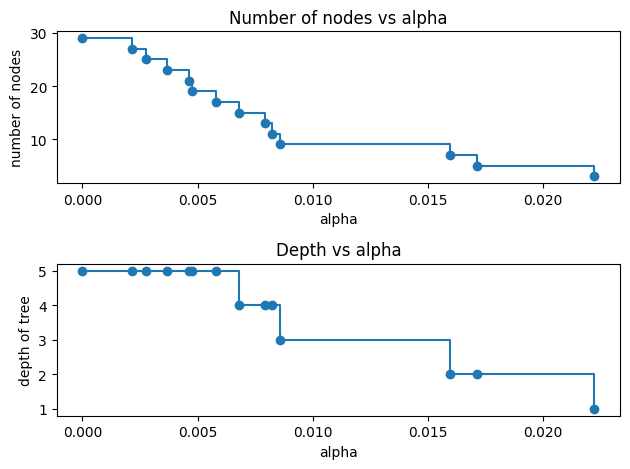

In [116]:
node_counts = [dt.tree_.node_count for dt in dts]
depth = [dt.tree_.max_depth for dt in dts]
fig, ax = plt.subplots(2, 1)
ax[0].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("number of nodes")
ax[0].set_title("Number of nodes vs alpha")
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("depth of tree")
ax[1].set_title("Depth vs alpha")
fig.tight_layout()

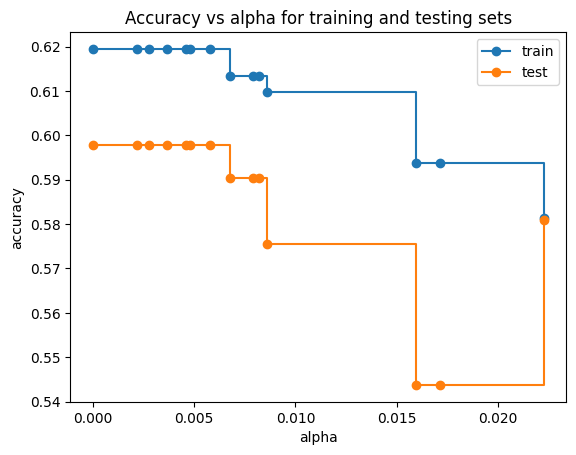

In [117]:
train_scores = [dt.score(X_train80, y_train80) for dt in dts]
test_scores = [dt.score(X_test20, y_test20) for dt in dts]

fig, ax = plt.subplots()
ax.set_xlabel("alpha")
ax.set_ylabel("accuracy")
ax.set_title("Accuracy vs alpha for training and testing sets")
ax.plot(ccp_alphas, train_scores, marker="o", label="train", drawstyle="steps-post")
ax.plot(ccp_alphas, test_scores, marker="o", label="test", drawstyle="steps-post")
ax.legend()
plt.show()

<Axes: xlabel='alpha'>

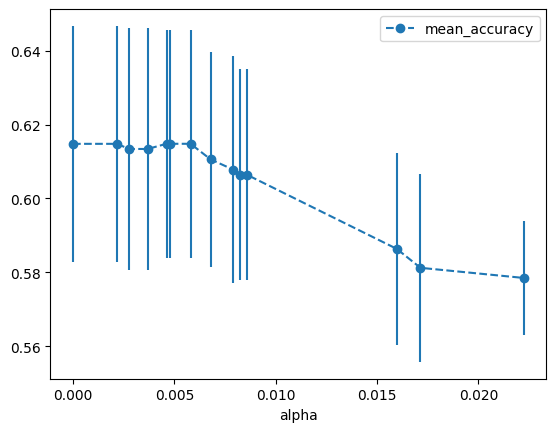

In [118]:
# Controlliamo i valori di alpha per vedere quale è più "consistente" nei dati
# vale a dire, quale valore di alpha ha la media più alta
alpha_loop_values = []
for ccp_alpha in ccp_alphas:
    dt = DecisionTreeClassifier(
        **grid_search_dt.best_params_,
        ccp_alpha=ccp_alpha,
        random_state=42,
    )
    scores = cross_val_score(dt, X_train80, y_train80, cv=20)
    alpha_loop_values.append([ccp_alpha, np.mean(scores), np.std(scores)])

alpha_results = pd.DataFrame(alpha_loop_values, columns=['alpha', 'mean_accuracy', 'std'])
alpha_results.plot(x='alpha', 
                   y='mean_accuracy', 
                   yerr='std', 
                   marker='o', 
                   linestyle='--')

In [119]:
# prendo il valore di alpha che ha la media più alta con cv
subset = alpha_results[(alpha_results['alpha'] >= 0.0) 
              & (alpha_results['alpha'] < 0.010)]

ideal_alpha = subset.loc[subset['mean_accuracy'].idxmax(), 'alpha']
ideal_alpha = float(ideal_alpha)
print("Miglior valore di alpha:", ideal_alpha)

Miglior valore di alpha: 0.00461291374398512


In [120]:
#
# Creo il modello con il valore di alpha ideale
# Split: 80/20
# Mostro la CM per vedere la distribuzione dei valori predetti
#

pruned_dt = DecisionTreeClassifier(
        random_state=42, 
        ccp_alpha=ideal_alpha,
        **grid_search_dt.best_params_
    )
pruned_dt.fit(X_train80, y_train80)
print("Train accuracy:", accuracy_score(y_true=y_train80, y_pred=pruned_dt.predict(X_train80)))
print("Test accuracy:", accuracy_score(y_true=y_test20, y_pred=pruned_dt.predict(X_test20)))

cv_scores = cross_val_score(pruned_dt, X_train80, y_train80, cv=20, scoring="accuracy")

print(f"Cross-Validation Accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Train accuracy: 0.6194690265486725
Test accuracy: 0.5977653631284916
Cross-Validation Accuracy: 0.6148 ± 0.0309


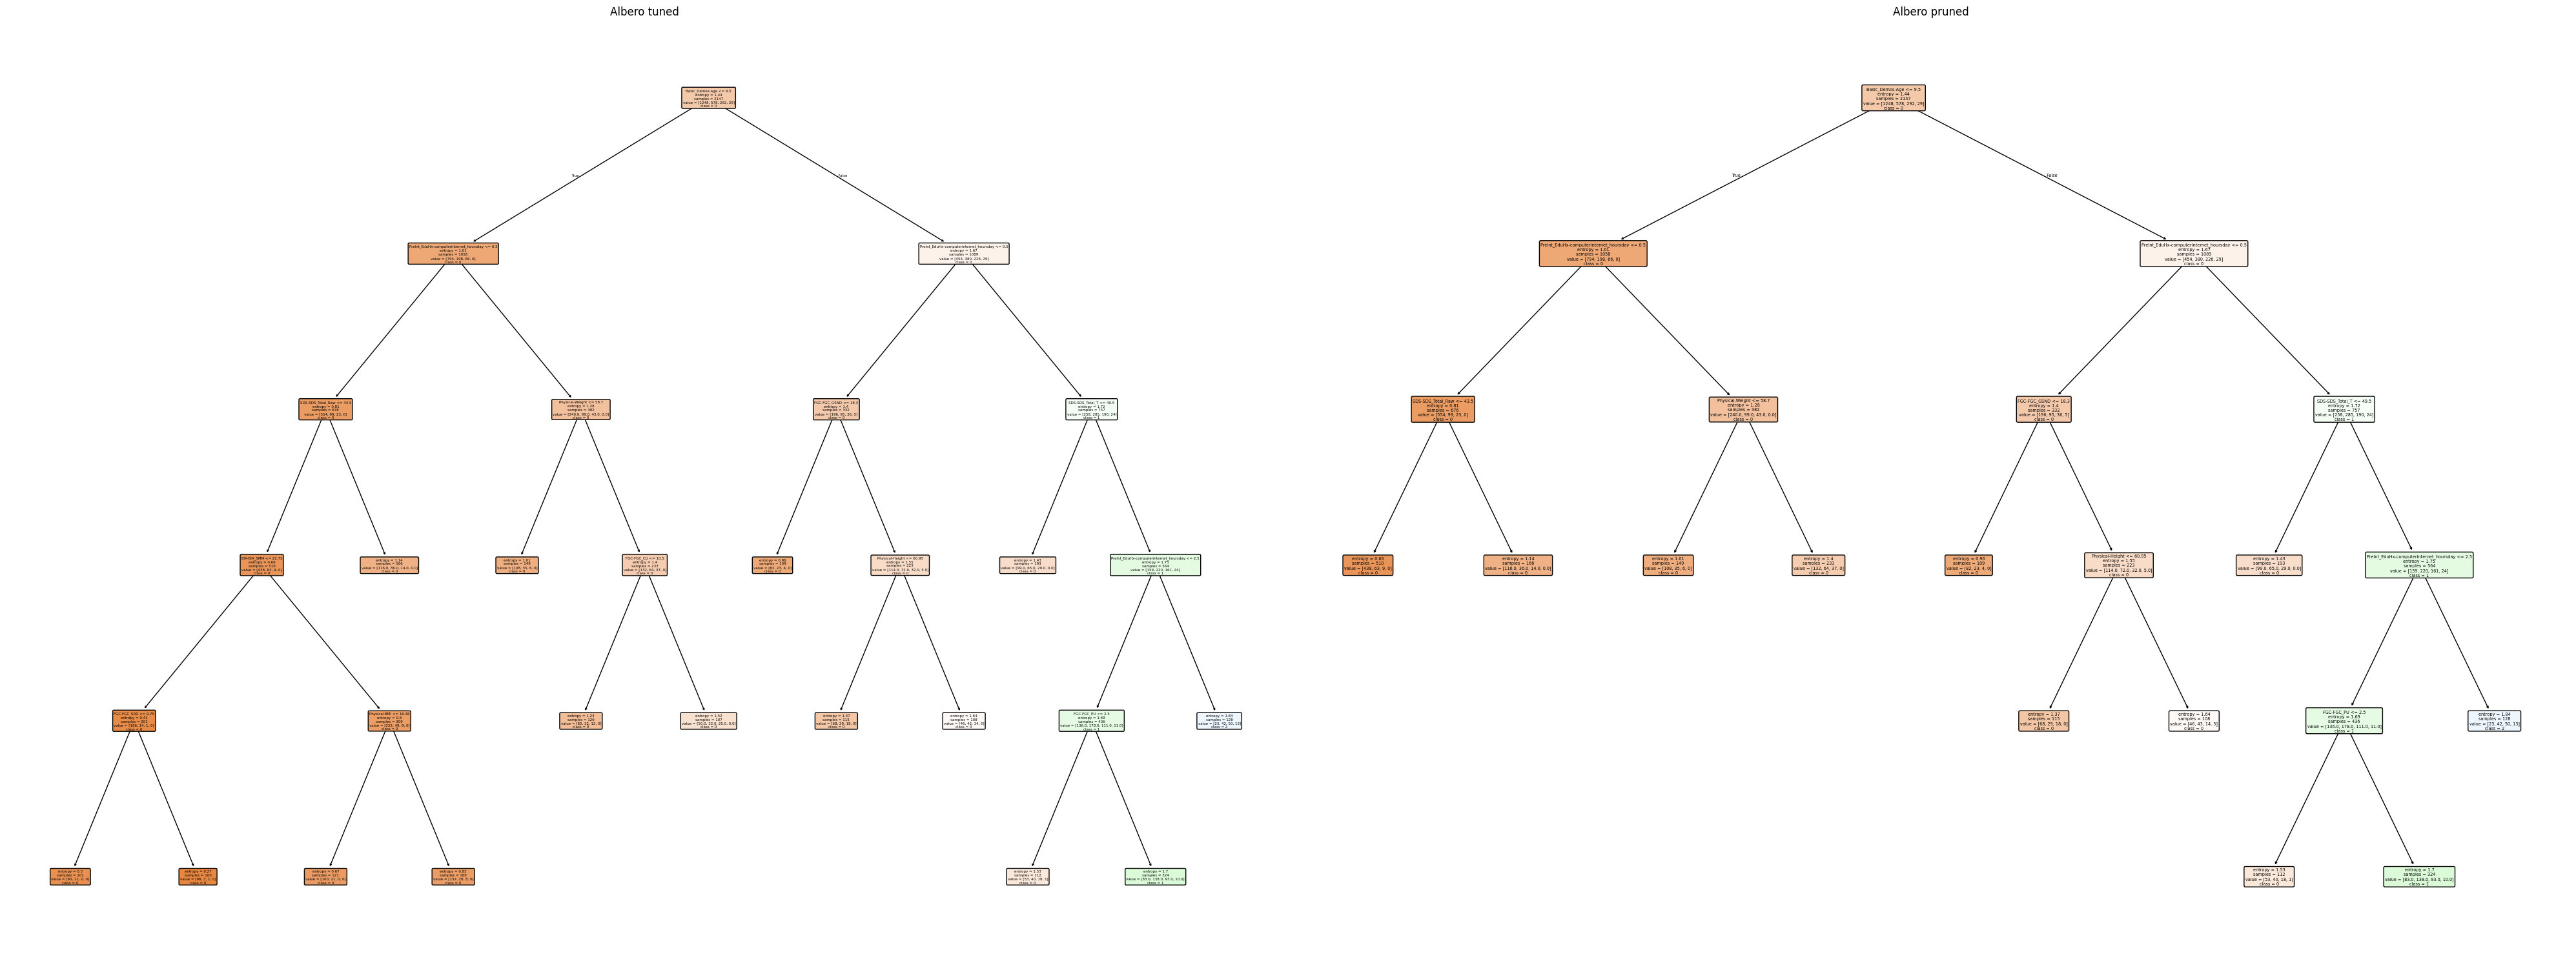

In [ ]:
#
# I due alberi a confronto
#
fig, axes = plt.subplots(1, 2, figsize=(40, 15))  # 1 riga, 2 colonne

plot_tree(tuned_dt, filled=True, feature_names=X_train80.columns, class_names=["0", "1", "2", "3"], rounded=True,
          proportion=False, precision=2, ax=axes[0])
axes[0].set_title("Albero tuned")

plot_tree(pruned_dt, filled=True, feature_names=X_train80.columns, class_names=["0", "1", "2", "3"], rounded=True, 
          proportion=False, precision=2, ax=axes[1])
axes[1].set_title("Albero pruned")

plt.tight_layout()
plt.show()


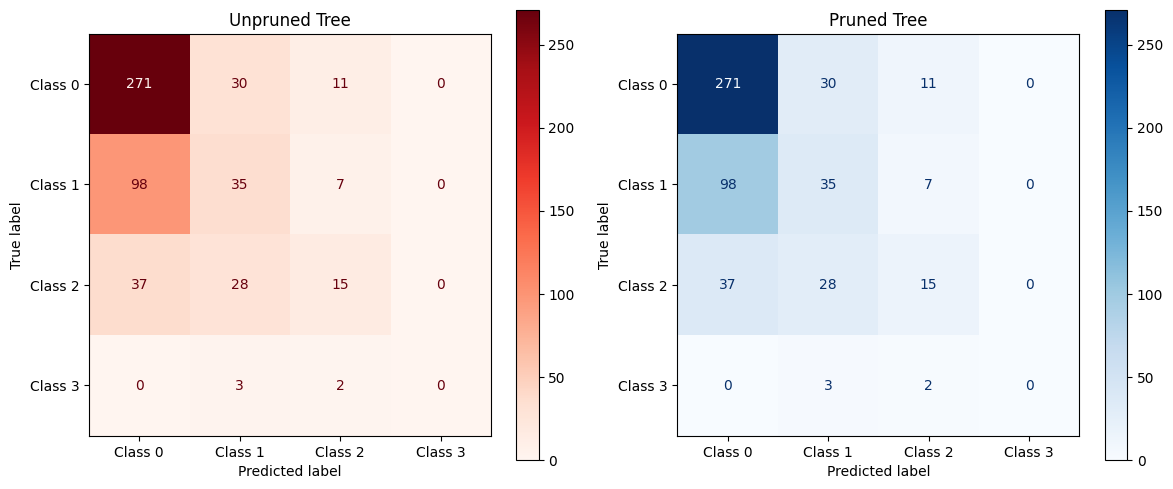

In [122]:
# Le due confusion matrix a confronto

cm_unpruned = confusion_matrix(y_test20, tuned_dt.predict(X_test20))
cm_pruned = confusion_matrix(y_test20, pruned_dt.predict(X_test20))

# Confusion Matrix dei 2 modelli
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
disp_unpruned = ConfusionMatrixDisplay(confusion_matrix=cm_unpruned, display_labels=["Class 0", "Class 1", "Class 2", "Class 3"])
disp_unpruned.plot(ax=axes[0], cmap="Reds")
axes[0].set_title("Unpruned Tree")

disp_pruned = ConfusionMatrixDisplay(confusion_matrix=cm_pruned, display_labels=["Class 0", "Class 1", "Class 2", "Class 3"])
disp_pruned.plot(ax=axes[1], cmap="Blues")
axes[1].set_title("Pruned Tree")

plt.tight_layout()
plt.show()

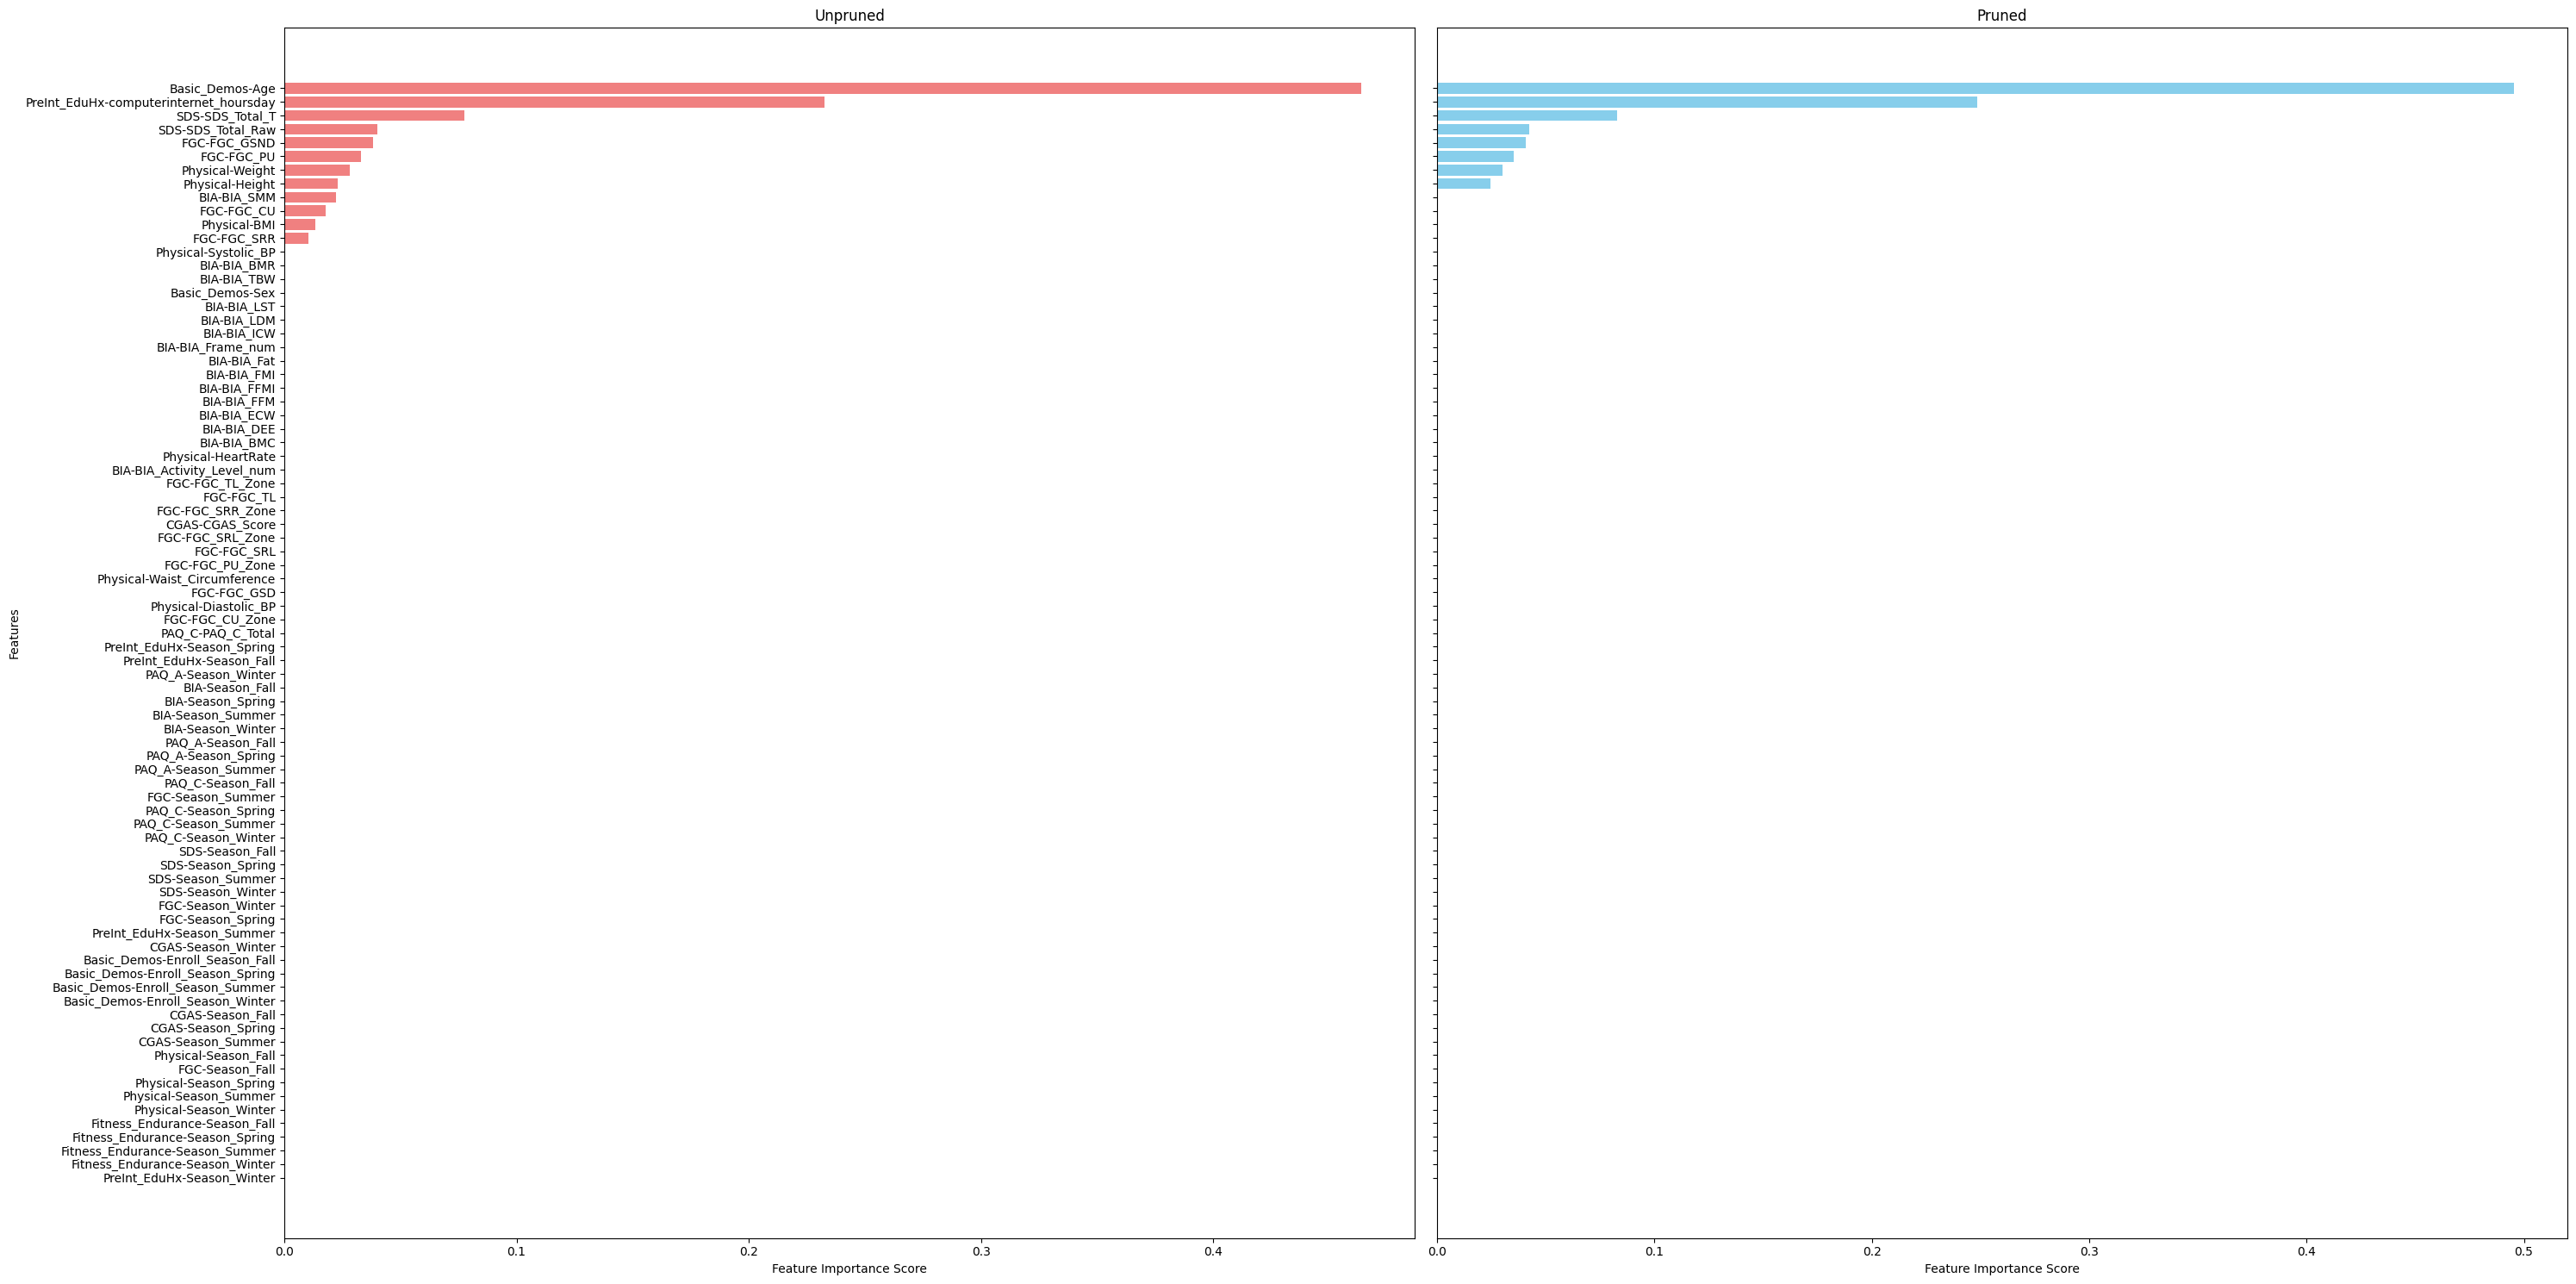

In [123]:
importances_unpruned = tuned_dt.feature_importances_
importances_pruned = pruned_dt.feature_importances_

sorted_idx_unpruned = np.argsort(importances_unpruned)[::-1]
sorted_idx_pruned = np.argsort(importances_pruned)[::-1]
sorted_features_unpruned = X_train80.columns[sorted_idx_unpruned]
sorted_features_pruned = X_train80.columns[sorted_idx_pruned]

fig, axes = plt.subplots(1, 2, figsize=(30, 15), sharey=True)

axes[0].barh(sorted_features_unpruned, importances_unpruned[sorted_idx_unpruned], color='lightcoral')
axes[0].set_xlabel("Feature Importance Score")
axes[0].set_ylabel("Features")
axes[0].set_title("Unpruned")
axes[0].invert_yaxis()

# Pruned tree plot
axes[1].barh(sorted_features_pruned, importances_pruned[sorted_idx_pruned], color='skyblue')
axes[1].set_xlabel("Feature Importance Score")
axes[1].set_title("Pruned")

plt.tight_layout()
plt.show()

Numero ottimale di feature: 7


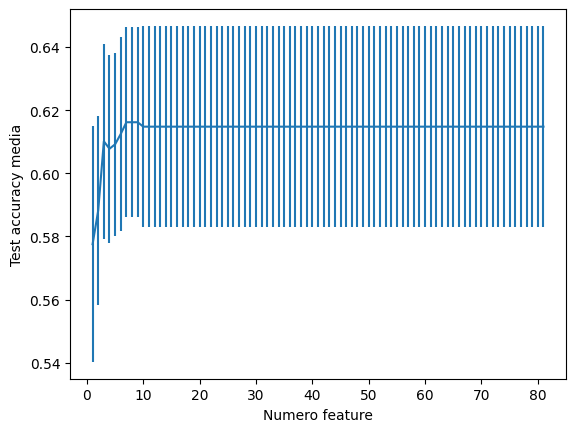

In [131]:
base_dt = DecisionTreeClassifier(**grid_search_dt.best_params_, random_state=42)
rfecv = RFECV(
    estimator=base_dt,
    step=1,
    cv=20,
    scoring="accuracy",
    min_features_to_select=1,
    n_jobs=-1,
)
rfecv.fit(X_train80, y_train80)

print(f"Numero ottimale di feature: {rfecv.n_features_}")

cv_results = pd.DataFrame(rfecv.cv_results_)
plt.figure()
plt.xlabel("Numero feature")
plt.ylabel("Test accuracy media")
plt.errorbar(x=cv_results["n_features"], y=cv_results["mean_test_score"], yerr=cv_results["std_test_score"],)
plt.show()

In [132]:
selected_features_dt = X.columns[rfecv.support_]
print("Feature selezionate:", list(selected_features_dt))

X_train_rfecv_dt = X_train80[selected_features_dt]
X_test_rfecv_dt = X_test20[selected_features_dt]

rfecv_dt = DecisionTreeClassifier(**grid_search_dt.best_params_, random_state=42)
rfecv_dt.fit(X_train_rfecv_dt, y_train80)

print("Train accuracy:", accuracy_score(y_true=y_train80, y_pred=rfecv_dt.predict(X_train_rfecv_dt)))
print("Test accuracy:", accuracy_score(y_true=y_test20, y_pred=rfecv_dt.predict(X_test_rfecv_dt)))

cv_scores = cross_val_score(rfecv_dt, X_train_rfecv_dt, y_train80, cv=20, scoring='accuracy')
print(f"Accuratezza media con cross-validation: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Feature selezionate: ['Basic_Demos-Age', 'Physical-Height', 'Physical-Weight', 'FGC-FGC_GSND', 'FGC-FGC_PU', 'SDS-SDS_Total_Raw', 'PreInt_EduHx-computerinternet_hoursday']
Train accuracy: 0.6194690265486725
Test accuracy: 0.5977653631284916
Accuratezza media con cross-validation: 0.6185 ± 0.0296


In [126]:
#################
# Random Forest #
#################

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train80, y_train80)

print("train acc:", accuracy_score(y_true=y_train80, y_pred=rf.predict(X_train80)))
print("test acc:", accuracy_score(y_true=y_test20, y_pred=rf.predict(X_test20)))

cv_scores = cross_val_score(rf, X_train80, y_train80, cv=20, scoring='accuracy')
print(f"CV Accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

train acc: 1.0
test acc: 0.5884543761638734
CV Accuracy: 0.590 ± 0.033


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_grid_rf = {'max_depth': [5, 7, 10],
                 'min_samples_split': [2, 4, 6, 8],
                 'max_leaf_nodes': [None, 5, 10, 20, 30],
                 'min_samples_leaf': [1, 5, 10, 15],
                 'n_estimators': [100, 150, 200, 300],
                 'min_impurity_decrease': [0.0, 0.001, 0.003],
                 'max_samples': [None, 0.3, 0.5, 0.7],
                }

rf = RandomForestClassifier(random_state=42)
grid_search_rf = RandomizedSearchCV(estimator=rf, param_distributions=param_grid_rf, cv=20, n_jobs=-1, 
                                    verbose=0, scoring='accuracy', n_iter=50)
grid_search_rf.fit(X_train80, y_train80)
print("Best Parameters:", grid_search_rf.best_params_)

tuned_rf = grid_search_rf.best_estimator_

train_acc = accuracy_score(y_true=y_train80, y_pred=tuned_rf.predict(X_train80))
test_acc = accuracy_score(y_true=y_test20, y_pred=tuned_rf.predict(X_test20))
print(f"Train Accuracy: {train_acc:.3f}")
print(f"Test Accuracy: {test_acc:.3f}")

scores = cross_val_score(tuned_rf, X_train80, y_train80, cv=20, scoring='accuracy')
print(f"Cross-Validation Accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

feature_importances = tuned_rf.feature_importances_
importance_df = pd.Series(feature_importances, index=X_train80.columns).sort_values(ascending=False)

print(importance_df.head(10))

Best Parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 5, 'min_impurity_decrease': 0.001, 'max_samples': None, 'max_leaf_nodes': 30, 'max_depth': 7}
Train Accuracy: 0.687
Test Accuracy: 0.600
Cross-Validation Accuracy: 0.6115 ± 0.0336
Basic_Demos-Age                           0.087469
PreInt_EduHx-computerinternet_hoursday    0.084604
Physical-Height                           0.071304
SDS-SDS_Total_Raw                         0.052851
SDS-SDS_Total_T                           0.044474
Physical-Weight                           0.044329
FGC-FGC_CU                                0.037314
BIA-BIA_LDM                               0.034814
BIA-BIA_SMM                               0.032936
BIA-BIA_LST                               0.029607
dtype: float64


Numero ottimale di feature: 9


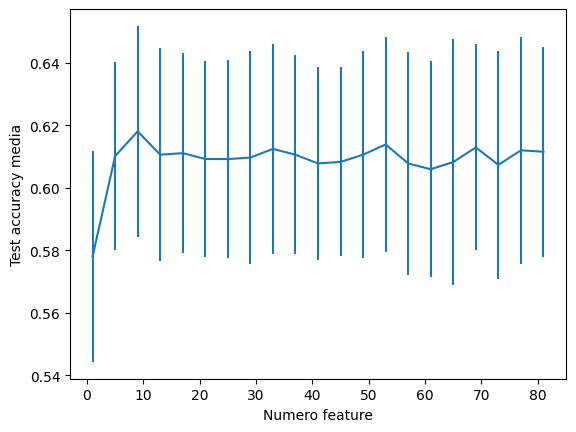

In [168]:
base_rf = RandomForestClassifier(**grid_search_rf.best_params_, random_state=42)
rfecv = RFECV(
    estimator=base_rf,
    step=4,
    cv=20,
    scoring="accuracy",
    min_features_to_select=1,
    n_jobs=-1,
)
rfecv.fit(X_train80, y_train80)
print(f"Numero ottimale di feature: {rfecv.n_features_}")

cv_results = pd.DataFrame(rfecv.cv_results_)
plt.figure()
plt.xlabel("Numero feature")
plt.ylabel("Test accuracy media")
plt.errorbar(x=cv_results["n_features"], y=cv_results["mean_test_score"], yerr=cv_results["std_test_score"],)
plt.show()

In [169]:
selected_features_rf = X_train80.columns[rfecv.support_]
print("Feature selezionate:", list(selected_features_rf))

X_train_rfecv_rf = X_train80[selected_features_rf]
X_test_rfecv_rf = X_test20[selected_features_rf]

rfecv_rf = RandomForestClassifier(**grid_search_rf.best_params_, random_state=42 )
rfecv_rf.fit(X_train_rfecv_rf, y_train80)

print("Train accuracy:", accuracy_score(y_true=y_train80, y_pred=rfecv_rf.predict(X_train_rfecv_rf)))
print("Test accuracy:", accuracy_score(y_true=y_test20, y_pred=rfecv_rf.predict(X_test_rfecv_rf)))

cv_scores = cross_val_score(rfecv_rf, X_train_rfecv_rf, y_train80, cv=20, scoring='accuracy')
print(f"Accuratezza media con cross-validation: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Feature selezionate: ['Basic_Demos-Age', 'Physical-Height', 'Physical-Weight', 'FGC-FGC_CU', 'BIA-BIA_LDM', 'BIA-BIA_SMM', 'SDS-SDS_Total_Raw', 'SDS-SDS_Total_T', 'PreInt_EduHx-computerinternet_hoursday']
Train accuracy: 0.6744294364229158
Test accuracy: 0.5921787709497207
Accuratezza media con cross-validation: 0.6213 ± 0.0321


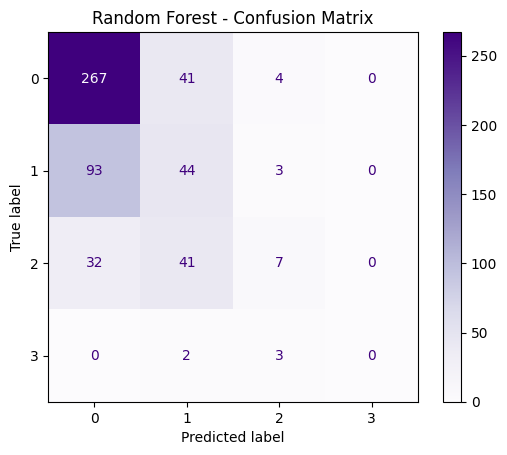

In [171]:
cm = confusion_matrix(y_test20, rfecv_rf.predict(X_test_rfecv_rf))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Purples)
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [172]:
###########
# XGBoost #
###########

df_with_na = df_with_na.astype(float)
df_with_na = df_with_na.round(2)

X = df_with_na.drop(columns=['sii'])
y = df_with_na['sii']

X_train80, X_test20, y_train80, y_test20 = train_test_split(X, y, test_size=0.20, random_state=42)

In [173]:
xgBoost = XGBClassifier()
xgBoost.fit(X_train80, y_train80)

print("train acc:", accuracy_score(y_true=y_train80, y_pred=xgBoost.predict(X_train80)))
print("test acc:", accuracy_score(y_true=y_test20, y_pred=xgBoost.predict(X_test20)))

cv_scores = cross_val_score(xgBoost, X_train80, y_train80, cv=20, scoring='accuracy')
print(f"CV Accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

train acc: 1.0
test acc: 0.5716945996275605
CV Accuracy: 0.585 ± 0.043


In [174]:
param_dist_xg = {
    'max_depth': [3, 6, 9, 12],
    'gamma': [0, 2, 4, 6, 8, 10],
    'reg_alpha': [0, 50, 100, 150, 200],
    'reg_lambda': [0, 1, 2, 3, 4, 5],
    'colsample_bytree': [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [0, 2, 4, 6, 8, 10],
    'learning_rate': [0.01, 0.05, 0.1, 0.2, 0.3],
    'subsample': [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    'n_estimators': [50, 100, 200, 300, 400, 500]
}

xgBoost = XGBClassifier(random_state=42)
random_search_xg = RandomizedSearchCV(estimator=xgBoost, param_distributions=param_dist_xg, cv=20, 
                                    n_jobs=-1, verbose=0, scoring='accuracy', n_iter=50)
random_search_xg.fit(X_train80, y_train80)
print("Best Parameters:", random_search_xg.best_params_)

tuned_xg = random_search_xg.best_estimator_

train_acc = accuracy_score(y_true=y_train80, y_pred=tuned_xg.predict(X_train80))
test_acc = accuracy_score(y_true=y_test20, y_pred=tuned_xg.predict(X_test20))
print(f"Train Accuracy: {train_acc:.3f}")
print(f"Test Accuracy: {test_acc:.3f}")

scores = cross_val_score(tuned_xg, X_train80, y_train80, cv=20, scoring='accuracy')
print(f"Cross-Validation Accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

feature_importances = tuned_xg.feature_importances_
importance_df = pd.Series(feature_importances, index=X_train80.columns).sort_values(ascending=False)
print(importance_df.head(10))

Best Parameters: {'subsample': 0.8, 'reg_lambda': 5, 'reg_alpha': 0, 'n_estimators': 400, 'min_child_weight': 2, 'max_depth': 9, 'learning_rate': 0.05, 'gamma': 8, 'colsample_bytree': 1.0}
Train Accuracy: 0.627
Test Accuracy: 0.583
Cross-Validation Accuracy: 0.6143 ± 0.0262
Basic_Demos-Age                           0.117162
Physical-Height                           0.072036
PreInt_EduHx-computerinternet_hoursday    0.058554
BIA-BIA_LDM                               0.044293
FGC-FGC_CU                                0.043634
SDS-SDS_Total_Raw                         0.042743
FGC-FGC_PU                                0.041444
PAQ_C-PAQ_C_Total                         0.040437
SDS-SDS_Total_T                           0.038638
Physical-Weight                           0.038582
dtype: float32


Numero ottimale di feature: 9


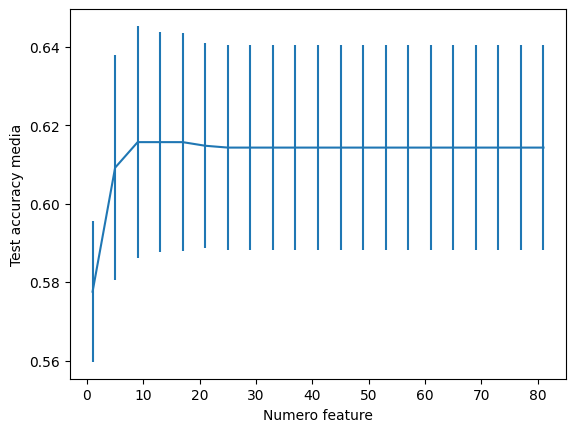

In [175]:
base_xg = XGBClassifier(**random_search_xg.best_params_, random_state=42)
rfecv = RFECV(
    estimator=base_xg,
    step=4,
    cv=20,
    scoring="accuracy",
    min_features_to_select=1,
    n_jobs=-1,
)
rfecv.fit(X_train80, y_train80)
print(f"Numero ottimale di feature: {rfecv.n_features_}")

cv_results = pd.DataFrame(rfecv.cv_results_)
plt.figure()
plt.xlabel("Numero feature")
plt.ylabel("Test accuracy media")
plt.errorbar(x=cv_results["n_features"], y=cv_results["mean_test_score"], yerr=cv_results["std_test_score"])
plt.show()

In [176]:
selected_features_xg = X_train80.columns[rfecv.support_]
print("Feature selezionate:", list(selected_features_xg))

X_train_rfecv_xg = X_train80[selected_features_xg]
X_test_rfecv_xg = X_test20[selected_features_xg]

rfecv_xg = XGBClassifier(**random_search_xg.best_params_, random_state=42 )
rfecv_xg.fit(X_train_rfecv_xg, y_train80)

print("Train accuracy:", accuracy_score(y_true=y_train80, y_pred=rfecv_xg.predict(X_train_rfecv_xg)))
print("Test accuracy:", accuracy_score(y_true=y_test20, y_pred=rfecv_xg.predict(X_test_rfecv_xg)))

cv_scores = cross_val_score(rfecv_xg, X_train_rfecv_xg, y_train80, cv=20, scoring='accuracy')
print(f"Accuratezza media con cross-validation: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Feature selezionate: ['Basic_Demos-Age', 'Physical-Height', 'FGC-FGC_CU', 'FGC-FGC_PU', 'BIA-BIA_LDM', 'PAQ_C-PAQ_C_Total', 'SDS-SDS_Total_Raw', 'SDS-SDS_Total_T', 'PreInt_EduHx-computerinternet_hoursday']
Train accuracy: 0.6204005589194225
Test accuracy: 0.5828677839851024
Accuratezza media con cross-validation: 0.6148 ± 0.0265


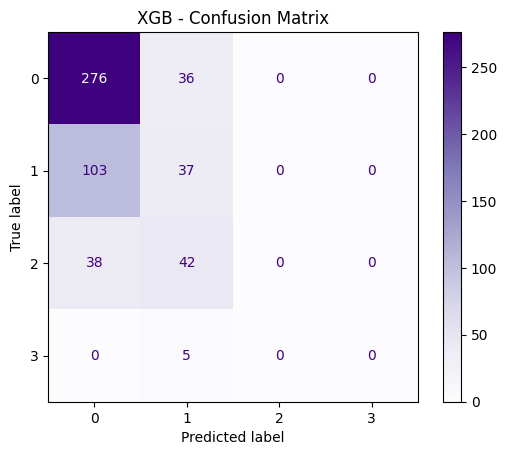

In [177]:
cm = confusion_matrix(y_test20, rfecv_xg.predict(X_test_rfecv_xg))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Purples)
plt.title("XGB - Confusion Matrix")
plt.show()

In [178]:
############
# LightGBM #
############

lgbm = LGBMClassifier(verbose=-1, random_state=42)
lgbm.fit(X_train80, y_train80)

print("train acc:", accuracy_score(y_true=y_train80, y_pred=lgbm.predict(X_train80)))
print("test acc:", accuracy_score(y_true=y_test20, y_pred=lgbm.predict(X_test20)))

cv_scores = cross_val_score(lgbm, X_train80, y_train80, cv=5, scoring='accuracy')
print(f"CV Accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")


train acc: 0.999534233814625
test acc: 0.5735567970204841
CV Accuracy: 0.585 ± 0.011


In [179]:
param_dist_lgbm = {
    'max_depth': [3, 6, 9, 12],
    'min_split_gain': [0, 0.1, 0.2, 0.3, 0.5],
    'reg_alpha': [0, 50, 100, 150, 200],
    'reg_lambda': [0, 1, 2, 3, 4, 5],
    'colsample_bytree': [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [0.001, 0.01, 0.1, 1, 10],
    'learning_rate': [0.01, 0.05, 0.1, 0.2, 0.3],
    'subsample': [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    'n_estimators': [50, 100, 200, 300, 400, 500]
}

lgbm = LGBMClassifier(verbose=-1, random_state=42)
random_search_lgbm = RandomizedSearchCV(estimator=lgbm, param_distributions=param_dist_lgbm, cv=20, 
                                    n_jobs=-1, verbose=0, scoring='accuracy', n_iter=50)
random_search_lgbm.fit(X_train80, y_train80)
print("Best Parameters:", random_search_lgbm.best_params_)

tuned_lgbm = random_search_lgbm.best_estimator_

train_acc = accuracy_score(y_true=y_train80, y_pred=tuned_lgbm.predict(X_train80))
test_acc = accuracy_score(y_true=y_test20, y_pred=tuned_lgbm.predict(X_test20))
print(f"Train Accuracy: {train_acc:.3f}")
print(f"Test Accuracy: {test_acc:.3f}")

scores = cross_val_score(tuned_lgbm, X_train80, y_train80, cv=20, scoring='accuracy')
print(f"Cross-Validation Accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

feature_importances = tuned_lgbm.feature_importances_
importance_df = pd.Series(feature_importances, index=X_train80.columns).sort_values(ascending=False)
print(importance_df.head(10))

Best Parameters: {'subsample': 0.6, 'reg_lambda': 2, 'reg_alpha': 50, 'n_estimators': 100, 'min_split_gain': 0.5, 'min_child_weight': 0.001, 'max_depth': 12, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
Train Accuracy: 0.622
Test Accuracy: 0.579
Cross-Validation Accuracy: 0.6189 ± 0.0316
PreInt_EduHx-computerinternet_hoursday    82
Physical-Height                           73
SDS-SDS_Total_Raw                         64
Basic_Demos-Age                           59
FGC-FGC_CU                                51
SDS-SDS_Total_T                           35
BIA-BIA_LDM                               30
Physical-Weight                           18
FGC-FGC_GSND                               7
FGC-FGC_GSD                                7
dtype: int32


/Users/gabrielearmani/Desktop/Università/3 anno/data_and_web_mining/progetto/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/gabrielearmani/Desktop/Università/3 anno/data_and_web_mining/progetto/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/gabrielearmani/Desktop/Università/3 anno/data_and_web_mining/progetto/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/gabrielearmani/Desktop/Università/3 anno/data_and_web_mining/progetto/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier

Numero ottimale di feature: 45


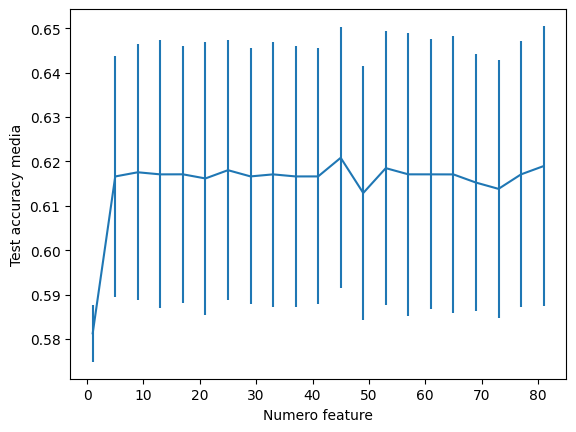

In [180]:
base_lgbm = LGBMClassifier(**random_search_lgbm.best_params_, random_state=42)
rfecv = RFECV(
    estimator=base_lgbm,
    step=4,
    cv=20,
    scoring="accuracy",
    min_features_to_select=1,
    n_jobs=-1,
)
rfecv.fit(X_train80, y_train80)
print(f"Numero ottimale di feature: {rfecv.n_features_}")

cv_results = pd.DataFrame(rfecv.cv_results_)
plt.figure()
plt.xlabel("Numero feature")
plt.ylabel("Test accuracy media")
plt.errorbar(x=cv_results["n_features"], y=cv_results["mean_test_score"], yerr=cv_results["std_test_score"])
plt.show()

In [181]:
selected_features_lgbm = X_train80.columns[rfecv.support_]
print("Feature selezionate:", list(selected_features_lgbm))

X_train_rfecv_lgbm = X_train80[selected_features_lgbm]
X_test_rfecv_lgbm = X_test20[selected_features_lgbm]

rfecv_lgbm = LGBMClassifier(**random_search_lgbm.best_params_, random_state=42)
rfecv_lgbm.fit(X_train_rfecv_lgbm, y_train80)

print("Train accuracy:", accuracy_score(y_true=y_train80, y_pred=rfecv_lgbm.predict(X_train_rfecv_lgbm)))
print("Test accuracy:", accuracy_score(y_true=y_test20, y_pred=rfecv_lgbm.predict(X_test_rfecv_lgbm)))

cv_scores = cross_val_score(rfecv_lgbm, X_train_rfecv_lgbm, y_train80, cv=20, scoring='accuracy')
print(f"Accuratezza media con cross-validation: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Feature selezionate: ['Basic_Demos-Age', 'Basic_Demos-Sex', 'CGAS-CGAS_Score', 'Physical-BMI', 'Physical-Height', 'Physical-Weight', 'Physical-Waist_Circumference', 'Physical-Diastolic_BP', 'Physical-HeartRate', 'Physical-Systolic_BP', 'FGC-FGC_CU', 'FGC-FGC_CU_Zone', 'FGC-FGC_GSND', 'FGC-FGC_GSD', 'FGC-FGC_PU', 'FGC-FGC_PU_Zone', 'FGC-FGC_SRL', 'FGC-FGC_SRL_Zone', 'FGC-FGC_SRR', 'FGC-FGC_SRR_Zone', 'BIA-BIA_BMC', 'BIA-BIA_BMR', 'BIA-BIA_DEE', 'BIA-BIA_Fat', 'BIA-BIA_ICW', 'BIA-BIA_LDM', 'BIA-BIA_SMM', 'SDS-SDS_Total_Raw', 'SDS-SDS_Total_T', 'PreInt_EduHx-computerinternet_hoursday', 'CGAS-Season_Summer', 'Physical-Season_Summer', 'Physical-Season_Winter', 'Fitness_Endurance-Season_Winter', 'FGC-Season_Fall', 'FGC-Season_Spring', 'FGC-Season_Summer', 'FGC-Season_Winter', 'BIA-Season_Fall', 'BIA-Season_Spring', 'BIA-Season_Summer', 'BIA-Season_Winter', 'PAQ_A-Season_Fall', 'PAQ_A-Season_Spring', 'PAQ_A-Season_Summer']
Train accuracy: 0.623660922217047
Test accuracy: 0.5791433891992551
Ac

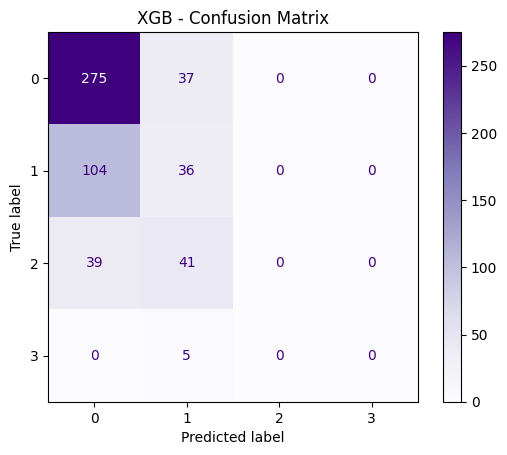

In [182]:
cm = confusion_matrix(y_test20, rfecv_lgbm.predict(X_test_rfecv_lgbm))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Purples)
plt.title("XGB - Confusion Matrix")
plt.show()